## 1. Compreensão dos Dados

#### [1] Carregar os dados e imprimir as primeiras linhas. Examinar a estrutura básica e identificar o tipo de dados de cada atributo.

In [ ]:
import pandas as pd

# Ler o ficheiro
file_path_csv = '/content/heart_disease_uci.csv'

# Construir o dataframe
heart_data = pd.read_csv(file_path_csv)


# Mostrar as primeiras linhas e a estrutura do conjunto de dados
heart_data.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


#### [2] Verificar a existência de valores em falta e identificar colunas que possam requerer limpeza ou transformação adicional

In [ ]:
heart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


#### [3] Calcular estatísticas básicas (média, mediana, etc.) e analisar a distribuição de cada atributo.

In [ ]:
heart_data.describe()

,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


## 2. Exploração dos Dados

#### [1] Explore a distribuição da classe. Qual a variação entre casos positivos (doença) vs casos negativos (sem doença).

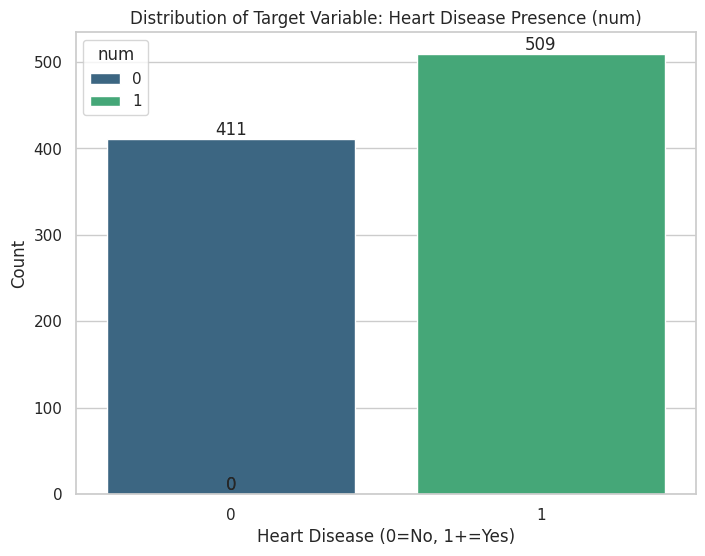

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 6))
ax = sns.countplot(data=heart_data, x='num', hue='num', palette="viridis") # Use 'viridis' color palette and set 'num' as hue
plt.title('Distribution of Target Variable: Heart Disease Presence (num)')
plt.xlabel('Heart Disease (0=No, 1+=Yes)')
plt.ylabel('Count')

# Add labels on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')

plt.show()

#### Conversão da classe em binário

In [ ]:
heart_data['num'] = (heart_data['num'] > 0).astype(int)

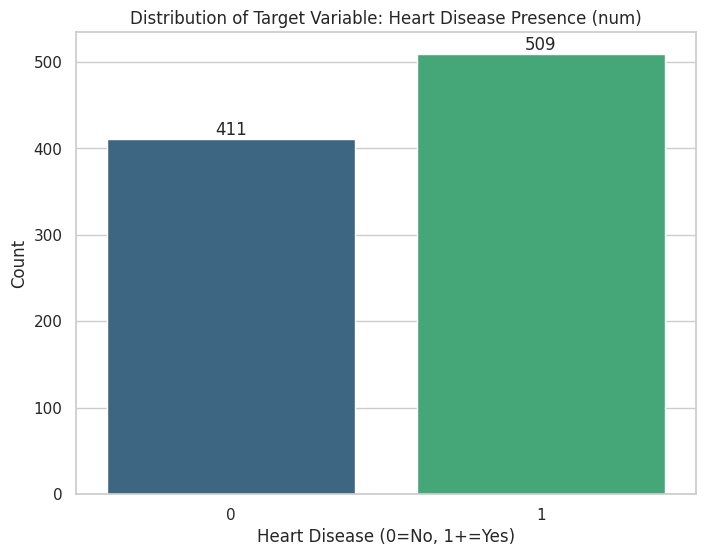

In [ ]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 6))
ax = sns.countplot(data=heart_data, x='num', hue='num', palette="viridis", legend=False)  # Use 'viridis' color palette and set 'num' as hue
plt.title('Distribution of Target Variable: Heart Disease Presence (num)')
plt.xlabel('Heart Disease (0=No, 1+=Yes)')
plt.ylabel('Count')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')

plt.show()

#### [2] Compare diferentes atributos (age, ejection fraction, sérum sodium, oldpeak) com a classe.

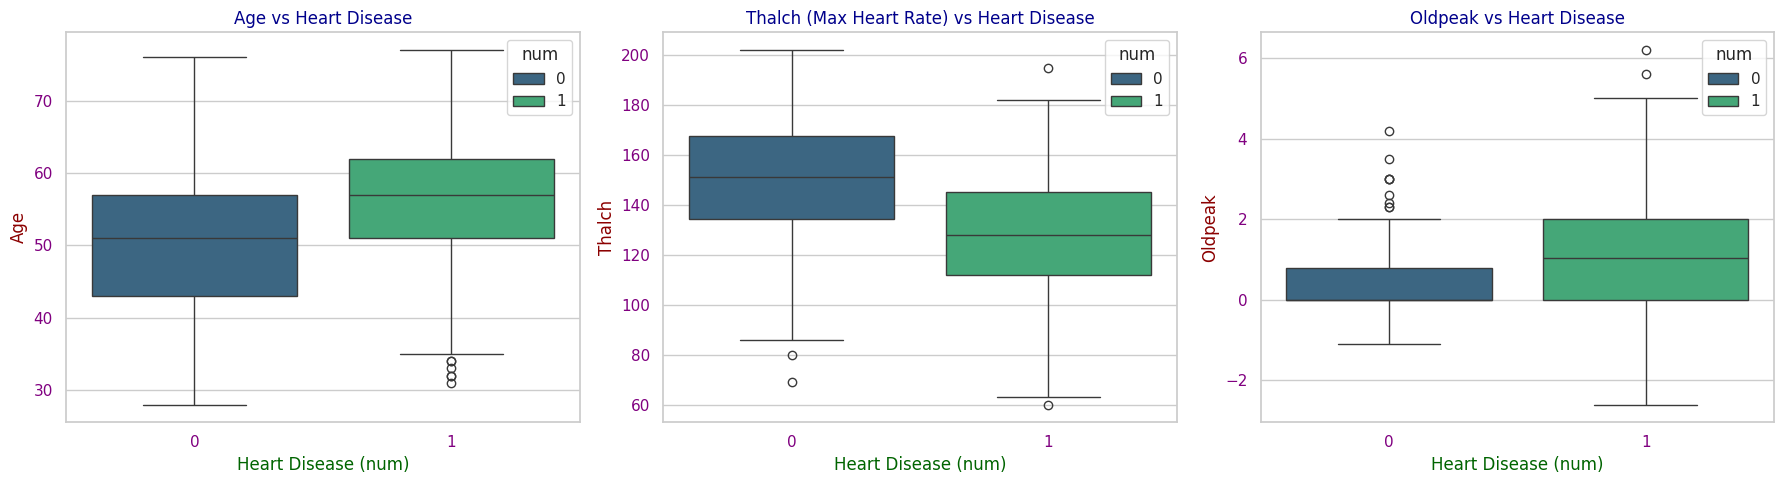

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

## Comparison for age vs Heart Disease
sns.boxplot(data=heart_data, x='num', y='age', hue='num', ax=axes[0], palette="viridis")
axes[0].set_title('Age vs Heart Disease', color='darkblue')
axes[0].set_xlabel('Heart Disease (num)', color='darkgreen')
axes[0].set_ylabel('Age', color='darkred')
axes[0].tick_params(axis='x', colors='purple')
axes[0].tick_params(axis='y', colors='purple')

## Comparison for Thalch vs Heart Disease
sns.boxplot(data=heart_data, x='num', y='thalch', hue='num', ax=axes[1], palette="viridis")
axes[1].set_title('Thalch (Max Heart Rate) vs Heart Disease', color='darkblue')
axes[1].set_xlabel('Heart Disease (num)', color='darkgreen')
axes[1].set_ylabel('Thalch', color='darkred')
axes[1].tick_params(axis='x', colors='purple')
axes[1].tick_params(axis='y', colors='purple')

## Comparison for Oldpeak vs Heart Disease
sns.boxplot(data=heart_data, x='num', y='oldpeak', hue='num', ax=axes[2], palette="viridis")
axes[2].set_title('Oldpeak vs Heart Disease', color='darkblue')
axes[2].set_xlabel('Heart Disease (num)', color='darkgreen')
axes[2].set_ylabel('Oldpeak', color='darkred')
axes[2].tick_params(axis='x', colors='purple')
axes[2].tick_params(axis='y', colors='purple')

plt.tight_layout()
plt.show()

#### (a) Use o histplot para comparar thalach e ca com a possibilidade de doença.

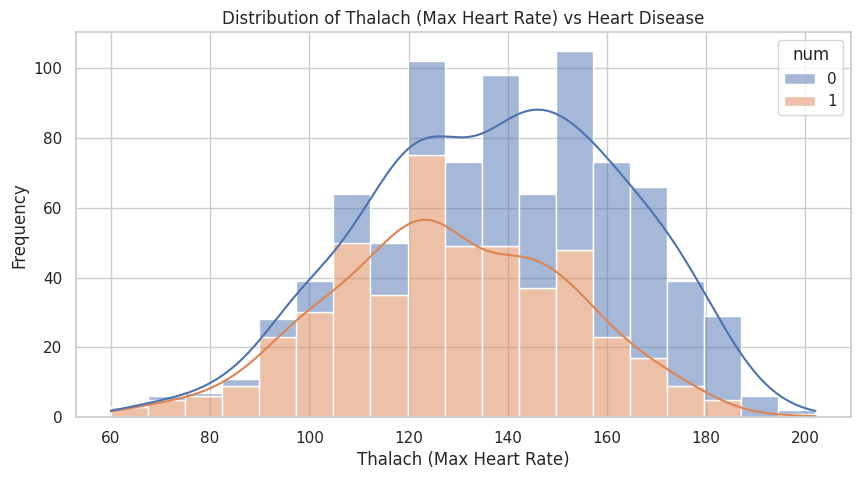

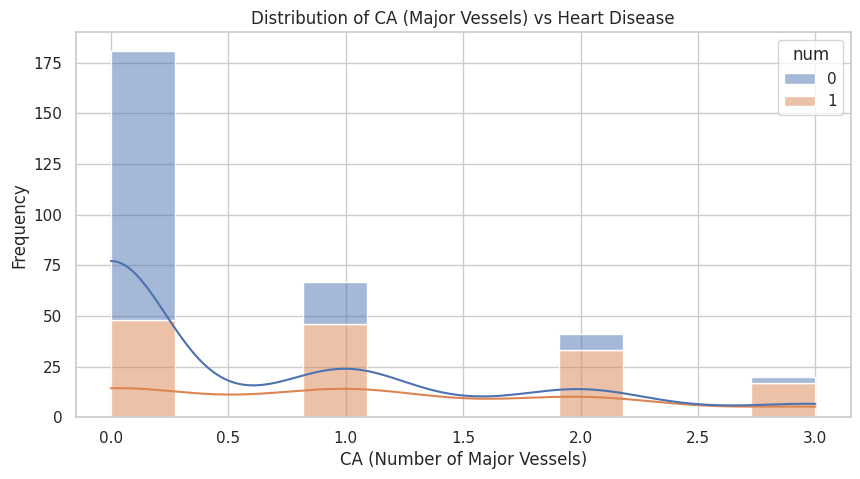

In [ ]:
# For the 'thalach' (max heart rate achieved) attribute
plt.figure(figsize=(10, 5))
sns.histplot(data=heart_data, x='thalch', hue='num', multiple="stack", kde=True)
plt.title("Distribution of Thalach (Max Heart Rate) vs Heart Disease")
plt.xlabel("Thalach (Max Heart Rate)")
plt.ylabel("Frequency")

#kde=True -> Kernel Density Estimate (KDE) curve

# For the 'ca' (number of major vessels colored by fluoroscopy) attribute
plt.figure(figsize=(10, 5))
sns.histplot(data=heart_data, x='ca', hue='num', multiple="stack", kde=True)
plt.title("Distribution of CA (Major Vessels) vs Heart Disease")
plt.xlabel("CA (Number of Major Vessels)")
plt.ylabel("Frequency")

plt.show()

#### [3]  Identifique padrões ou correlações entre os atributos, utilizando matrizes de correlação. Não utilize os atributos ‘id’ e ‘num’.

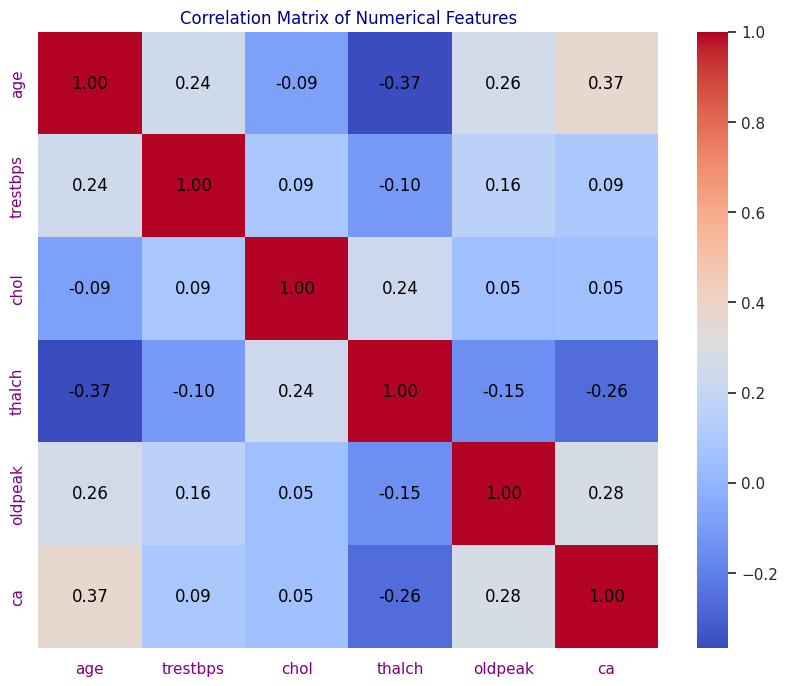

In [ ]:
# Select only numeric columns for the correlation matrix
numeric_columns = heart_data.select_dtypes(include='number').drop(columns=['id', 'num'])
correlation_matrix = numeric_columns.corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", annot_kws={'color': 'black'})
plt.title('Correlation Matrix of Numerical Features', color='darkblue')
plt.xticks(color='purple')
plt.yticks(color='purple')
plt.show()

## 3. Processamento de Dados

#### [1] Tratar os valores em falta identificados na fase de compreensão dos dados.

In [ ]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Define the threshold of 30% for missing values
missing_value_threshold = 0.3

# Iterate over the columns of the DataFrame
for column in heart_data.columns:
    # Calculate the percentage of missing values
    missing_percentage = heart_data[column].isnull().mean()

    # Check if the percentage of missing values is greater than the threshold
    if missing_percentage > missing_value_threshold:
        # Drop the column if it has more than 30% missing values
        heart_data = heart_data.drop(columns=[column])
        print(f"Column '{column}' dropped due to more than 30% missing values.")
    else:
        # Fill missing values
        if heart_data[column].dtype in ['float64', 'int64']:
            # Fill with the median for numerical columns
            heart_data[column] = heart_data[column].fillna(heart_data[column].median())
        else:
            # Fill with the mode for categorical columns
            heart_data[column] = heart_data[column].fillna(heart_data[column].mode()[0])
            heart_data[column] = heart_data[column].infer_objects()  # Ensure correct data types if needed


Column 'slope' dropped due to more than 30% missing values.
Column 'ca' dropped due to more than 30% missing values.
Column 'thal' dropped due to more than 30% missing values.


<ipython-input-18-4ba5fecf0017>:23: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  heart_data[column] = heart_data[column].fillna(heart_data[column].mode()[0])


In [ ]:
# validate
heart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  920 non-null    float64
 6   chol      920 non-null    float64
 7   fbs       920 non-null    bool   
 8   restecg   920 non-null    object 
 9   thalch    920 non-null    float64
 10  exang     920 non-null    bool   
 11  oldpeak   920 non-null    float64
 12  num       920 non-null    int64  
dtypes: bool(2), float64(4), int64(3), object(4)
memory usage: 81.0+ KB


#### [2] Escalar ou normalizar características numéricas para garantir consistência nos dados para a fase de modelação.

In [ ]:
scaler = StandardScaler()
numerical_features = heart_data.select_dtypes(include=['float64', 'int64']).columns.drop('num')
heart_data[numerical_features] = scaler.fit_transform(heart_data[numerical_features])

# Display the preprocessed data (first few rows)
heart_data.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
0,-1.730169,1.007386,Male,Cleveland,typical angina,0.705176,0.303643,True,lv hypertrophy,0.489727,False,1.368109,0
1,-1.726404,1.432034,Male,Cleveland,asymptomatic,1.518569,0.789967,False,lv hypertrophy,-1.181478,True,0.611589,1
2,-1.722639,1.432034,Male,Cleveland,asymptomatic,-0.650479,0.266939,False,lv hypertrophy,-0.345875,True,1.651804,1
3,-1.718873,-1.752828,Male,Cleveland,non-anginal,-0.108217,0.459634,False,normal,1.961979,False,2.502889,0
4,-1.715108,-1.328180,Female,Cleveland,atypical angina,-0.108217,0.037541,False,lv hypertrophy,1.365120,False,0.517024,0


#### [3] Codificar variáveis categóricas, se existirem, em valores numéricos.

In [ ]:
# Dictionary to store the encoders for each column
label_encoders = {}

# Apply LabelEncoder to all categorical columns and store the conversion information
for column in heart_data.select_dtypes(include=['object']).columns:
    # Create the encoder
    le = LabelEncoder()

    # Apply the encoder to the column and store it in the dictionary
    heart_data[column] = le.fit_transform(heart_data[column])
    label_encoders[column] = le

    # Add the value mappings for each column to the information list
    print(f"Coluna: {column}")
    for i, class_name in enumerate(le.classes_):
        print(f"  {class_name} -> {i}")

Coluna: sex
  Female -> 0
  Male -> 1
Coluna: dataset
  Cleveland -> 0
  Hungary -> 1
  Switzerland -> 2
  VA Long Beach -> 3
Coluna: cp
  asymptomatic -> 0
  atypical angina -> 1
  non-anginal -> 2
  typical angina -> 3
Coluna: restecg
  lv hypertrophy -> 0
  normal -> 1
  st-t abnormality -> 2


In [ ]:
heart_data.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
0,-1.730169,1.007386,1,0,3,0.705176,0.303643,True,0,0.489727,False,1.368109,0
1,-1.726404,1.432034,1,0,0,1.518569,0.789967,False,0,-1.181478,True,0.611589,1
2,-1.722639,1.432034,1,0,0,-0.650479,0.266939,False,0,-0.345875,True,1.651804,1
3,-1.718873,-1.752828,1,0,2,-0.108217,0.459634,False,1,1.961979,False,2.502889,0
4,-1.715108,-1.328180,0,0,1,-0.108217,0.037541,False,0,1.365120,False,0.517024,0


In [ ]:
heart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    float64
 1   age       920 non-null    float64
 2   sex       920 non-null    int64  
 3   dataset   920 non-null    int64  
 4   cp        920 non-null    int64  
 5   trestbps  920 non-null    float64
 6   chol      920 non-null    float64
 7   fbs       920 non-null    bool   
 8   restecg   920 non-null    int64  
 9   thalch    920 non-null    float64
 10  exang     920 non-null    bool   
 11  oldpeak   920 non-null    float64
 12  num       920 non-null    int64  
dtypes: bool(2), float64(6), int64(5)
memory usage: 81.0 KB


#### [4] Remover atributos desnecessários.

In [ ]:
heart_data = heart_data.drop(columns=['id'])

In [ ]:
heart_data.head()

,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
0,1.007386,1,0,3,0.705176,0.303643,True,0,0.489727,False,1.368109,0
1,1.432034,1,0,0,1.518569,0.789967,False,0,-1.181478,True,0.611589,1
2,1.432034,1,0,0,-0.650479,0.266939,False,0,-0.345875,True,1.651804,1
3,-1.752828,1,0,2,-0.108217,0.459634,False,1,1.961979,False,2.502889,0
4,-1.328180,0,0,1,-0.108217,0.037541,False,0,1.365120,False,0.517024,0


## 4. Modelação

#### [1] Dividir o conjunto de dados em conjuntos de treino e teste (80/20).

In [ ]:
from sklearn.model_selection import train_test_split

# Convert categorical features in X to one-hot encoded columns
X = heart_data.drop(columns=['num'])  # Features (excluding target)

# Only the target variable
y_binary = heart_data['num']

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y_binary, test_size=0.2, random_state=42)

#X_train.info()
#X_test.info()
#y_train.info()
#y_test.info()

#### [2] Construir um modelo de classificação simples (ex.: LogisticRegression) para prever a variável alvo.

In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the LogisticRegression model
logreg_model = LogisticRegression(max_iter=1000)  # Increased max_iter to ensure convergence
logreg_model.fit(X_train, y_train)

# Make predictions with the LogisticRegression model
y_pred_logreg = logreg_model.predict(X_test)

print('[INFO] - Logistic Regression predictions complete!!')

[INFO] - Logistic Regression predictions complete!!


#### [3] Experimentar com 2 modelos mais complexos (Random Forest e SVM).

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Initialize and train the RandomForest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions with the RandomForest model
y_pred_rf = rf_model.predict(X_test)

print('[INFO] - Random Forest predictions complete!!')

# Initialize and train the SVM model
svm_model = SVC(random_state=42)
svm_model.fit(X_train, y_train)

# Make predictions with the SVM model
y_pred_svm = svm_model.predict(X_test)

print('[INFO] - SVM predictions complete!!')

[INFO] - Random Forest predictions complete!!
[INFO] - SVM predictions complete!!


## 5. Avaliação

#### [1] Avaliar o desempenho de cada modelo utilizando métricas como precisão, precisão específica, recall e F1-score

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

logreg_report = classification_report(y_test, y_pred_logreg)
rf_report = classification_report(y_test, y_pred_rf)
svm_report = classification_report(y_test, y_pred_svm)


print(f"LogisticRegression Report:\n", logreg_report)
print(f"DecisionTrees Report:\n", rf_report)
print(f"SVM LogisticRegression Report:\n", svm_report)

LogisticRegression Report:
               precision    recall  f1-score   support

           0       0.72      0.83      0.77        75
           1       0.87      0.78      0.82       109

    accuracy                           0.80       184
   macro avg       0.79      0.80      0.80       184
weighted avg       0.81      0.80      0.80       184

DecisionTrees Report:
               precision    recall  f1-score   support

           0       0.78      0.81      0.80        75
           1       0.87      0.84      0.86       109

    accuracy                           0.83       184
   macro avg       0.82      0.83      0.83       184
weighted avg       0.83      0.83      0.83       184

SVM LogisticRegression Report:
               precision    recall  f1-score   support

           0       0.82      0.81      0.82        75
           1       0.87      0.88      0.88       109

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85  

In [ ]:
from sklearn.metrics import classification_report

# Convert classification reports to dictionaries
logreg_report_dict = classification_report(y_test, y_pred_logreg, output_dict=True)
rf_report_dict = classification_report(y_test, y_pred_rf, output_dict=True)
svm_report_dict = classification_report(y_test, y_pred_svm, output_dict=True)

# Convert dictionaries to DataFrames and ensure no NaNs are present
logreg_df = pd.DataFrame(logreg_report_dict).transpose().fillna(0)
rf_df = pd.DataFrame(rf_report_dict).transpose().fillna(0)
svm_df = pd.DataFrame(svm_report_dict).transpose().fillna(0)

# Combine both DataFrames into a single table for comparison
comparison_df = pd.concat([logreg_df, rf_df, svm_df], axis=1, keys=['Logistic Regression', 'Random Forest', 'SVM']).fillna(0)

# Reset any problematic indexing with MultiIndex and ensure no NaNs are present
comparison_df.columns = pd.MultiIndex.from_product([['Logistic Regression', 'Random Forest', 'SVM'], logreg_df.columns])
comparison_df = comparison_df.map(lambda x: 0 if pd.isna(x) else x)  # Replace any NaN entries with 0

# Style the DataFrame for display
styled_df = comparison_df.style.set_caption("Comparison of Classification Reports").format(precision=2).set_table_styles([
    {'selector': 'caption', 'props': 'caption-side: top; font-weight: bold; font-size: 16px; text-align: center;'},
    {'selector': 'th', 'props': 'font-weight: bold; background-color: #f0f0f0;'},
    {'selector': 'td', 'props': 'text-align: center;'},
])

# Display the styled DataFrame
styled_df

#### [2] Calcule a acuidade global do modelo. Recorra a um gráfico de barras para apresentar a comparação dos modelos.

In [ ]:
from sklearn.metrics import accuracy_score

# Calculate accuracy for Logistic Regression and Random Forest
logreg_accuracy = accuracy_score(y_test, y_pred_logreg)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

# Display the results
print(f"Logistic Regression Accuracy: {logreg_accuracy:.2f}")
print(f"Random Forest Accuracy: {rf_accuracy:.2f}")
print(f"SVM Accuracy: {svm_accuracy:.2f}")

Logistic Regression Accuracy: 0.80
Random Forest Accuracy: 0.83
SVM Accuracy: 0.85


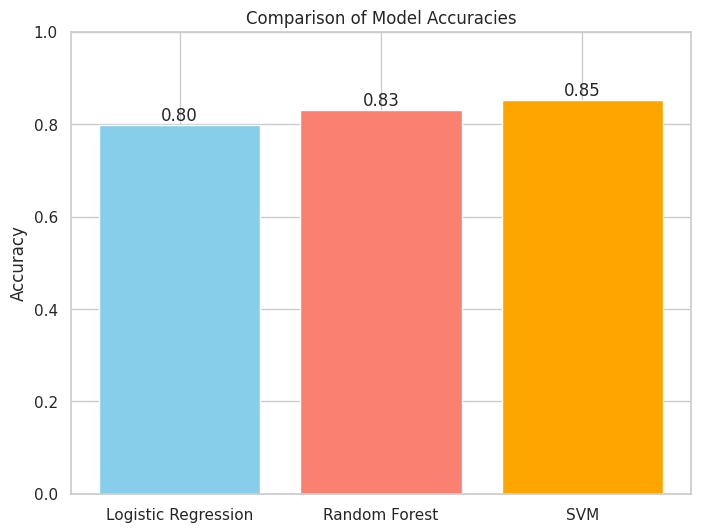

In [ ]:
# Accuracy values for each model
models = ['Logistic Regression', 'Random Forest','SVM']
accuracies = [logreg_accuracy, rf_accuracy, svm_accuracy]

# Plotting the accuracies
plt.figure(figsize=(8, 6))
bars = plt.bar(models, accuracies, color=['skyblue', 'salmon','orange'])
plt.ylim(0, 1)  # Setting y-axis to range from 0 to 1 for clarity
plt.ylabel('Accuracy')
plt.title('Comparison of Model Accuracies')

# Adding labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval, f'{yval:.2f}', ha='center', va='bottom')

plt.show()

#### [3] Gerar uma matriz de confusão para cada modelo e interpretar os resultados

In [ ]:
logreg_cm = confusion_matrix(y_test, y_pred_logreg)
rf_cm = confusion_matrix(y_test, y_pred_rf)
svm_cm = confusion_matrix(y_test, y_pred_svm)

print(f"Confusion Matrix - Logistic Regression \n",logreg_cm)
print(f"Confusion Matrix - Random Forest \n",rf_cm)
print(f"Confusion Matrix - SVM \n",svm_cm)

Confusion Matrix - Logistic Regression 
 [[62 13]
 [24 85]]
Confusion Matrix - Random Forest 
 [[61 14]
 [17 92]]
Confusion Matrix - SVM 
 [[61 14]
 [13 96]]


### Versão aprimorada da Matriz de Confusão

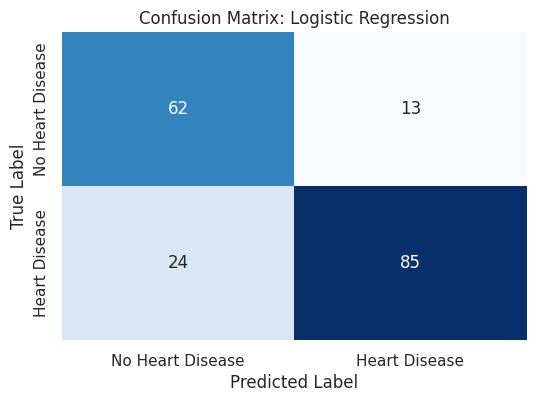

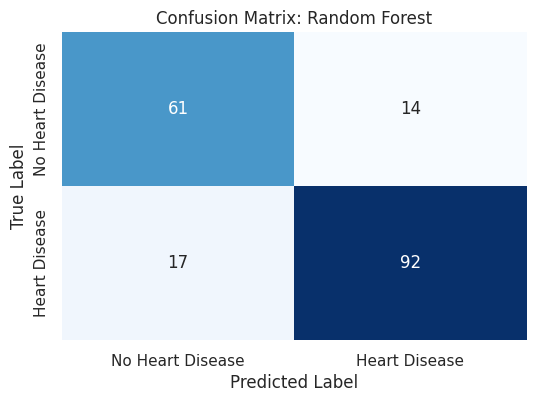

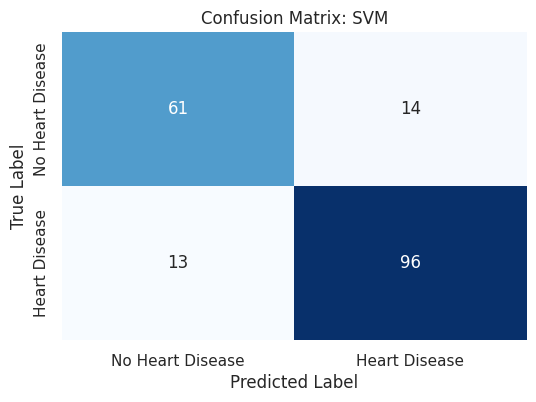

In [ ]:
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=['No Heart Disease', 'Heart Disease'],
                yticklabels=['No Heart Disease', 'Heart Disease'])
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(title)
    plt.show()


plot_confusion_matrix(y_test, y_pred_logreg, "Confusion Matrix: Logistic Regression")
plot_confusion_matrix(y_test, y_pred_rf, "Confusion Matrix: Random Forest")
plot_confusion_matrix(y_test, y_pred_svm, "Confusion Matrix: SVM")

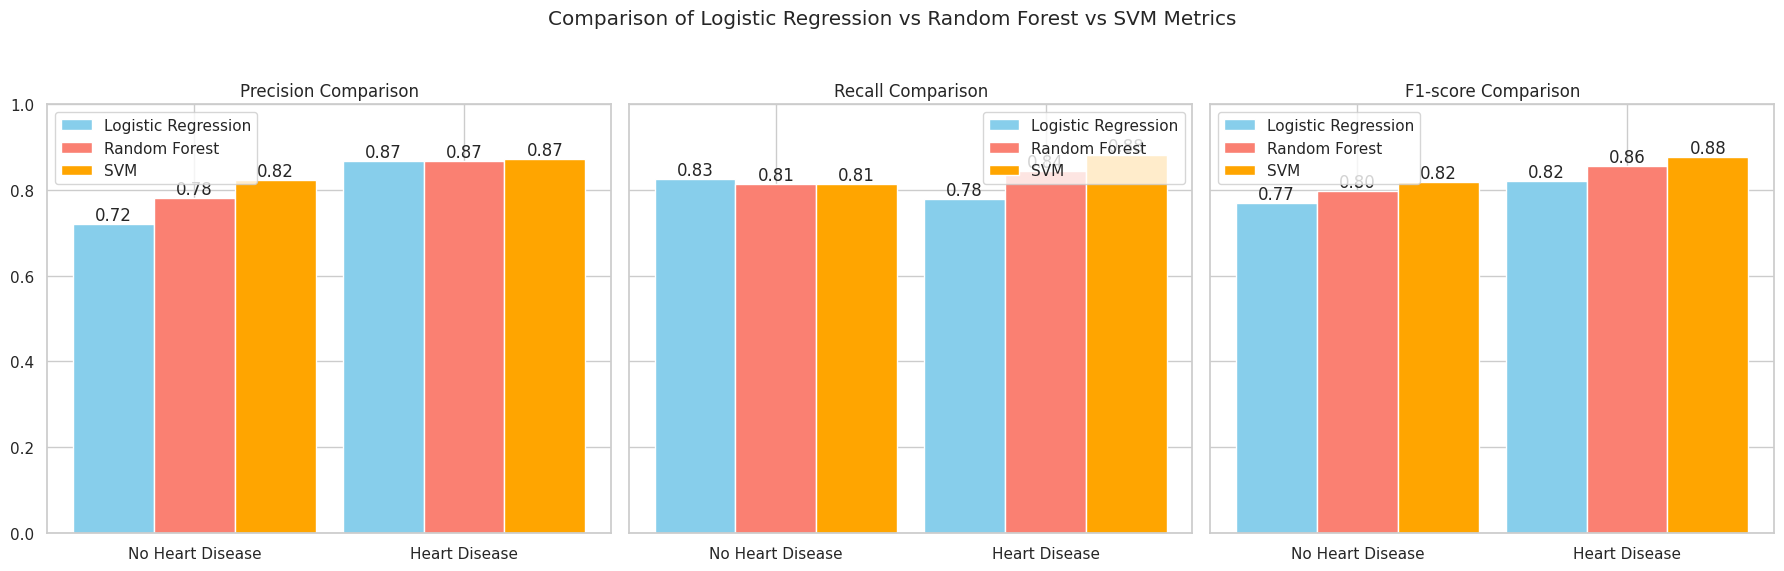

In [ ]:
import numpy as np

# Define metrics and labels for plotting
metrics = ['precision', 'recall', 'f1-score']
categories = ['No Heart Disease', 'Heart Disease']
logreg_scores = [logreg_report_dict['0'], logreg_report_dict['1']]
rf_scores = [rf_report_dict['0'], rf_report_dict['1']]
svm_scores = [svm_report_dict['0'], svm_report_dict['1']]

# Initialize plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Plot each metric
for i, metric in enumerate(metrics):
    logreg_metric = [logreg_scores[0][metric], logreg_scores[1][metric]]
    rf_metric = [rf_scores[0][metric], rf_scores[1][metric]]
    svm_metric = [svm_scores[0][metric], svm_scores[1][metric]]
    x = np.arange(len(categories))

    # Adjust the positions to avoid overlap
    bars1 = axes[i].bar(x - 0.3, logreg_metric, width=0.3, label="Logistic Regression", color='skyblue')
    bars2 = axes[i].bar(x, rf_metric, width=0.3, label="Random Forest", color='salmon')
    bars3 = axes[i].bar(x + 0.3, svm_metric, width=0.3, label="SVM", color='orange')

    axes[i].set_xticks(x)
    axes[i].set_xticklabels(categories)
    axes[i].set_title(f'{metric.capitalize()} Comparison')
    axes[i].set_ylim(0, 1)
    axes[i].legend()

    # Add labels on top of each bar
    for bar in bars1:
        axes[i].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():.2f}',
                     ha='center', va='bottom')
    for bar in bars2:
        axes[i].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():.2f}',
                     ha='center', va='bottom')
    for bar in bars3:
        axes[i].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{bar.get_height():.2f}',
                     ha='center', va='bottom')

# Adding a title
plt.suptitle('Comparison of Logistic Regression vs Random Forest vs SVM Metrics')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report

# Perform 5-fold cross-validation on the data
logreg_scores = cross_val_score(logreg_model, X_test, y_test, cv=5, scoring='accuracy')
rf_scores = cross_val_score(rf_model, X_test, y_test, cv=5, scoring='accuracy')
svm_scores = cross_val_score(svm_model, X_test, y_test, cv=5, scoring='accuracy')


# Print the cross-validation results
print(f"Logistic Regression Cross-Validation Accuracy: {logreg_scores.mean():.2f}")
print(f"Random Forest Cross-Validation Accuracy: {rf_scores.mean():.2f}")
print(f"SVM Cross-Validation Accuracy: {svm_scores.mean():.2f}")

Logistic Regression Cross-Validation Accuracy: 0.80
Random Forest Cross-Validation Accuracy: 0.85
SVM Cross-Validation Accuracy: 0.85
